In [10]:
"""
전체 파이프라인 (원본 파일 두 개만 있으면 처음부터 끝까지 재현)
필요 파일: g_patent_tsv.zip (내부: g_patent.tsv), g_cpc_current_tsv.zip (내부: g_cpc_current.tsv)

출력물:
  1) declining_subclasses_logistic.tsv  - 로지스틱(S-curve) 피팅으로 판별한 성숙/쇠퇴 subclass
  2) internal_rise_candidates.tsv       - 쇠퇴 subclass 내부에서 비중이 상승하는 main group
  3) jaccard_fusion_report.tsv          - 상위 후보 subclass들의 Jaccard 융합강도 상위 파트너
  4) subclass_year_counts.tsv           - subclass별 연도별 절대건수 (시계열 원본)
  5) maingroup_year_counts.tsv          - main group별 연도별 절대건수 (시계열 원본)
  6) trend_absolute.png, trend_share.png - 상위 후보 1개에 대한 시계열 그래프
"""

import zipfile
import csv
import io
from collections import defaultdict
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# ============================================================
# 0. 설정
# ============================================================
PATENT_ZIP = "g_patent.tsv.zip"
CPC_ZIP = "g_cpc_current.tsv.zip"
PATENT_TSV_NAME = "g_patent.tsv"
CPC_TSV_NAME = "g_cpc_current.tsv"

MIN_YEAR = 1976
MAX_YEAR = 2023
RECENT_YEARS = list(range(2010, MAX_YEAR + 1))

MIN_SUBCLASS_TOTAL = 100
MIN_MAINGROUP_AVG = 3
SATURATION_THRESHOLD = 0.9
MIN_COOCCUR_FOR_JACCARD = 3
TOP_N_SUBCLASS_FOR_JACCARD = 5

plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows. Mac이면 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

# ============================================================
# 1. g_patent.tsv -> patent_id : year
# ============================================================
print("[1/7] g_patent.tsv 로딩...")

def load_patent_years(zip_path, tsv_name):
    year_map = {}
    with zipfile.ZipFile(zip_path) as zf:
        with zf.open(tsv_name) as f:
            text = io.TextIOWrapper(f, encoding="utf-8")
            reader = csv.reader(text, delimiter="\t", quotechar='"')
            header = next(reader)
            idx_id = header.index("patent_id")
            idx_type = header.index("patent_type")
            idx_date = header.index("patent_date")
            for row in reader:
                if row[idx_type] != "utility":
                    continue
                date = row[idx_date]
                if len(date) < 4:
                    continue
                year_map[row[idx_id]] = int(date[:4])
    return year_map

patent_year = load_patent_years(PATENT_ZIP, PATENT_TSV_NAME)
print(f"  -> {len(patent_year):,}건\n")

# ============================================================
# 2. g_cpc_current.tsv 스트리밍 -> 연도별 집계 + Jaccard용 set
# ============================================================
print("[2/7] g_cpc_current.tsv 처리...")

subclass_year_new = defaultdict(lambda: defaultdict(int))
maingroup_year_new = defaultdict(lambda: defaultdict(int))
subclass_to_patents = defaultdict(set)

with zipfile.ZipFile(CPC_ZIP) as zf:
    with zf.open(CPC_TSV_NAME) as f:
        text = io.TextIOWrapper(f, encoding="utf-8")
        reader = csv.reader(text, delimiter="\t", quotechar='"')
        header = next(reader)
        idx_id = header.index("patent_id")
        idx_subclass = header.index("cpc_subclass")
        idx_group = header.index("cpc_group")
        idx_type = header.index("cpc_type")

        for row in reader:
            if row[idx_type] != "inventional":
                continue
            pid = row[idx_id]
            year = patent_year.get(pid)
            if year is None or year < MIN_YEAR or year > MAX_YEAR:
                continue
            subclass = row[idx_subclass]
            maingroup = row[idx_group].split("/")[0]

            subclass_year_new[subclass][year] += 1
            maingroup_year_new[maingroup][year] += 1
            subclass_to_patents[subclass].add(pid)

print(f"  -> subclass {len(subclass_year_new):,}개, main group {len(maingroup_year_new):,}개\n")

# ---- 시계열 원본 저장 (여기가 이전 버전에서 빠졌던 부분) ----
with open("subclass_year_counts.tsv", "w", encoding="utf-8") as f:
    for code, yd in subclass_year_new.items():
        for year, count in sorted(yd.items()):
            f.write(f"{code}\t{year}\t{count}\n")
print("  저장: subclass_year_counts.tsv")

with open("maingroup_year_counts.tsv", "w", encoding="utf-8") as f:
    for code, yd in maingroup_year_new.items():
        for year, count in sorted(yd.items()):
            f.write(f"{code}\t{year}\t{count}\n")
print("  저장: maingroup_year_counts.tsv\n")

# ============================================================
# 3. 로지스틱(S-curve) 피팅 -> 성숙/쇠퇴 subclass
# ============================================================
print("[3/7] 로지스틱 피팅...")

def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

def cumulative_series(year_counts, years):
    cum, running = [], 0
    for y in years:
        running += year_counts.get(y, 0)
        cum.append(running)
    return cum

all_years = list(range(MIN_YEAR, MAX_YEAR + 1))
decline_results = []

for subclass, yd in subclass_year_new.items():
    total_count = sum(yd.values())
    if total_count < MIN_SUBCLASS_TOTAL:
        continue
    cum = np.array(cumulative_series(yd, all_years), dtype=float)
    t = np.array(all_years, dtype=float)
    K0 = cum[-1] * 1.5 if cum[-1] > 0 else 1.0
    try:
        popt, _ = curve_fit(
            logistic, t, cum, p0=[K0, 0.3, t[len(t)//2]], maxfev=10000,
            bounds=([cum[-1], 0.001, t.min()], [cum[-1]*50, 5, t.max()+50])
        )
        K_est, r_est, t0_est = popt
        current_cum = cum[-1]
        ratio = current_cum / K_est if K_est > 0 else np.nan
        decline_results.append({
            "subclass": subclass, "K_est": K_est, "r_est": r_est, "t0_est": t0_est,
            "current_cum": current_cum, "ratio_to_K": ratio,
            "is_declining": ratio >= SATURATION_THRESHOLD, "total_count": total_count,
        })
    except (RuntimeError, ValueError):
        continue

declining_subclasses_info = sorted(
    [r for r in decline_results if r["is_declining"]], key=lambda x: -x["total_count"]
)
declining_subclasses = [r["subclass"] for r in declining_subclasses_info]
print(f"  -> 쇠퇴 subclass {len(declining_subclasses_info)}개\n")

with open("declining_subclasses_logistic.tsv", "w", encoding="utf-8") as f:
    f.write("subclass\tK_est\tr_est\tt0_est\tcurrent_cum\tratio_to_K\ttotal_count\n")
    for r in declining_subclasses_info:
        f.write(f"{r['subclass']}\t{r['K_est']:.1f}\t{r['r_est']:.4f}\t{r['t0_est']:.1f}\t"
                f"{r['current_cum']:.0f}\t{r['ratio_to_K']:.4f}\t{r['total_count']}\n")
print("  저장: declining_subclasses_logistic.tsv\n")

# ============================================================
# 4. 내부비중 상승 main group 스크리닝
# ============================================================
print("[4/7] 내부비중 상승 main group 탐색...")

def linreg_slope(x, y):
    n = len(x)
    mx, my = sum(x)/n, sum(y)/n
    num = sum((x[i]-mx)*(y[i]-my) for i in range(n))
    den = sum((x[i]-mx)**2 for i in range(n))
    return num/den if den != 0 else 0.0

internal_rise_candidates = []
for subclass in declining_subclasses:
    sub_yd = subclass_year_new.get(subclass, {})
    if not all(y in sub_yd for y in RECENT_YEARS):
        continue
    sub_vals = [sub_yd[y] for y in RECENT_YEARS]
    for group, gyd in maingroup_year_new.items():
        if not group.startswith(subclass):
            continue
        if not all(y in gyd for y in RECENT_YEARS):
            continue
        g_vals = [gyd[y] for y in RECENT_YEARS]
        if sum(g_vals)/len(g_vals) < MIN_MAINGROUP_AVG:
            continue
        internal_share = [g_vals[i]/sub_vals[i]*100 if sub_vals[i]>0 else 0 for i in range(len(RECENT_YEARS))]
        avg_share = sum(internal_share)/len(internal_share)
        if avg_share <= 0:
            continue
        slope = linreg_slope(RECENT_YEARS, internal_share)
        internal_rise_candidates.append({
            "upper_subclass": subclass, "lower_group": group,
            "avg_internal_share_pct": avg_share, "rel_slope_per_year": slope/avg_share,
            "avg_count": sum(g_vals)/len(g_vals),
        })

internal_rise_candidates.sort(key=lambda x: -x["rel_slope_per_year"])
print(f"  -> 후보 {len(internal_rise_candidates)}개\n")

with open("internal_rise_candidates.tsv", "w", encoding="utf-8") as f:
    f.write("upper_subclass\tlower_group\tavg_internal_share_pct\trel_slope_per_year\tavg_count\n")
    for c in internal_rise_candidates:
        f.write(f"{c['upper_subclass']}\t{c['lower_group']}\t{c['avg_internal_share_pct']:.2f}\t"
                f"{c['rel_slope_per_year']:.4f}\t{c['avg_count']:.1f}\n")
print("  저장: internal_rise_candidates.tsv\n")

# ============================================================
# 5. Jaccard 융합강도
# ============================================================
print("[5/7] Jaccard 융합강도 계산...")

def jaccard(a, b):
    set_a = subclass_to_patents.get(a, set())
    set_b = subclass_to_patents.get(b, set())
    if not set_a or not set_b:
        return 0.0, 0
    coo = len(set_a & set_b)
    denom = len(set_a) + len(set_b) - coo
    return (coo/denom if denom > 0 else 0.0), coo

top_targets, seen = [], set()
for c in internal_rise_candidates:
    if c["upper_subclass"] not in seen:
        top_targets.append(c["upper_subclass"]); seen.add(c["upper_subclass"])
    if len(top_targets) >= TOP_N_SUBCLASS_FOR_JACCARD:
        break

jaccard_rows = []
for target in top_targets:
    scores = []
    for other in subclass_to_patents.keys():
        if other == target:
            continue
        score, coo = jaccard(target, other)
        if coo >= MIN_COOCCUR_FOR_JACCARD:
            scores.append((other, score, coo))
    scores.sort(key=lambda x: -x[1])
    for partner, score, coo in scores[:10]:
        jaccard_rows.append((target, partner, score, coo))

with open("jaccard_fusion_report.tsv", "w", encoding="utf-8") as f:
    f.write("target_subclass\tpartner_subclass\tjaccard\tco_occurrence\n")
    for target, partner, score, coo in jaccard_rows:
        f.write(f"{target}\t{partner}\t{score:.4f}\t{coo}\n")
print("  저장: jaccard_fusion_report.tsv\n")

# ============================================================
# 6. 대표 사례 시계열 그래프 (내부비중 상승 1위 쌍 자동 선택)
# ============================================================
print("[6/7] 대표 사례 시계열 그래프 생성...")

top_pair = internal_rise_candidates[0]
UPPER_CODE = top_pair["upper_subclass"]
LOWER_CODE = top_pair["lower_group"]
GRAPH_YEARS = list(range(2010, MAX_YEAR + 1))

upper_vals = [subclass_year_new[UPPER_CODE].get(y, 0) for y in GRAPH_YEARS]
lower_vals = [maingroup_year_new[LOWER_CODE].get(y, 0) for y in GRAPH_YEARS]
share_vals = [lower_vals[i]/upper_vals[i]*100 if upper_vals[i] > 0 else 0 for i in range(len(GRAPH_YEARS))]

fig, ax1 = plt.subplots(figsize=(9, 5.5))
c_up, c_low = '#c0392b', '#1f6fb2'
ax1.plot(GRAPH_YEARS, upper_vals, color=c_up, linewidth=2.5, marker='o', markersize=5, label=f'{UPPER_CODE} (상위)')
ax1.set_xlabel('연도'); ax1.set_ylabel(f'{UPPER_CODE} 건수', color=c_up, fontsize=12)
ax1.tick_params(axis='y', labelcolor=c_up)
ax2 = ax1.twinx()
ax2.plot(GRAPH_YEARS, lower_vals, color=c_low, linewidth=2.5, marker='s', markersize=5, label=f'{LOWER_CODE} (하위)')
ax2.set_ylabel(f'{LOWER_CODE} 건수', color=c_low, fontsize=12)
ax2.tick_params(axis='y', labelcolor=c_low)
l1, lb1 = ax1.get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1+l2, lb1+lb2, loc='upper left', fontsize=10, frameon=False)
plt.title(f'{UPPER_CODE}(상위) vs {LOWER_CODE}(하위) 절대건수 추이', fontsize=13, pad=12)
fig.tight_layout()
plt.savefig('trend_absolute.png', dpi=200, bbox_inches='tight')
plt.close()

fig2, ax = plt.subplots(figsize=(9, 5))
ax.plot(GRAPH_YEARS, share_vals, color=c_low, linewidth=2.5, marker='o', markersize=5)
ax.fill_between(GRAPH_YEARS, share_vals, alpha=0.15, color=c_low)
ax.set_xlabel('연도'); ax.set_ylabel(f'{UPPER_CODE} 내 {LOWER_CODE} 비중 (%)', fontsize=12)
ax.set_title(f'상위({UPPER_CODE}) 대비 세부기술({LOWER_CODE}) 내부비중 추이', fontsize=13, pad=12)
ax.grid(alpha=0.3)
fig2.tight_layout()
plt.savefig('trend_share.png', dpi=200, bbox_inches='tight')
plt.close()

print(f"  자동 선택된 대표 사례: {UPPER_CODE} -> {LOWER_CODE}")
print("  저장: trend_absolute.png, trend_share.png\n")

# ============================================================
# 7. 요약 출력
# ============================================================
print("[7/7] 완료. 생성된 파일:")
print("  - declining_subclasses_logistic.tsv")
print("  - internal_rise_candidates.tsv")
print("  - jaccard_fusion_report.tsv")
print("  - subclass_year_counts.tsv")
print("  - maingroup_year_counts.tsv")
print("  - trend_absolute.png")
print("  - trend_share.png")

[1/7] g_patent.tsv 로딩...
  -> 8,531,961건

[2/7] g_cpc_current.tsv 처리...
  -> subclass 646개, main group 7,368개

  저장: subclass_year_counts.tsv
  저장: maingroup_year_counts.tsv

[3/7] 로지스틱 피팅...
  -> 쇠퇴 subclass 84개

  저장: declining_subclasses_logistic.tsv

[4/7] 내부비중 상승 main group 탐색...
  -> 후보 290개

  저장: internal_rise_candidates.tsv

[5/7] Jaccard 융합강도 계산...
  저장: jaccard_fusion_report.tsv

[6/7] 대표 사례 시계열 그래프 생성...
  자동 선택된 대표 사례: G11B -> G11B3
  저장: trend_absolute.png, trend_share.png

[7/7] 완료. 생성된 파일:
  - declining_subclasses_logistic.tsv
  - internal_rise_candidates.tsv
  - jaccard_fusion_report.tsv
  - subclass_year_counts.tsv
  - maingroup_year_counts.tsv
  - trend_absolute.png
  - trend_share.png


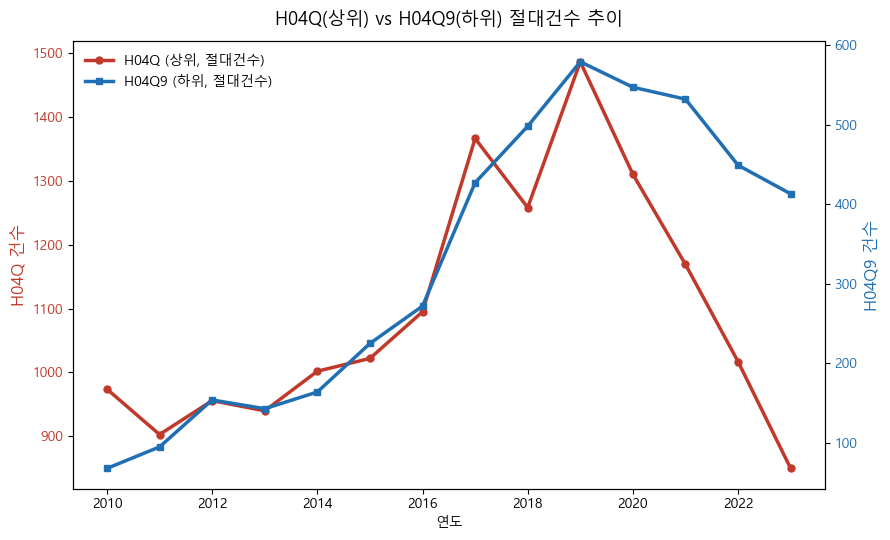

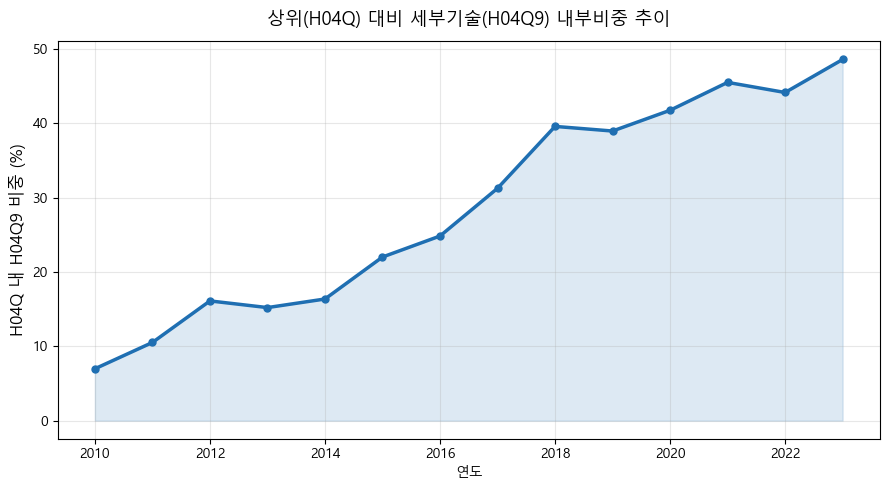

In [11]:
import matplotlib.pyplot as plt
from collections import defaultdict

# 한글 폰트 설정 (환경에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows
# plt.rcParams['font.family'] = 'AppleGothic'   # Mac
plt.rcParams['axes.unicode_minus'] = False

# ---- 1. 데이터 로드 ----
def load_counts(path):
    d = defaultdict(dict)
    with open(path, encoding='utf-8') as f:
        for line in f:
            code, year, count = line.strip().split('\t')
            d[code][int(year)] = int(count)
    return d

subclass_data = load_counts('subclass_year_counts.tsv')
maingroup_data = load_counts('maingroup_year_counts.tsv')

# ---- 2. 비교할 상위/하위 코드 지정 ----
UPPER_CODE = 'H04Q'
LOWER_CODE = 'H04Q9'
YEARS = list(range(2010, 2024))

upper_vals = [subclass_data[UPPER_CODE].get(y, 0) for y in YEARS]
lower_vals = [maingroup_data[LOWER_CODE].get(y, 0) for y in YEARS]
share_vals = [lower_vals[i] / upper_vals[i] * 100 if upper_vals[i] > 0 else 0
              for i in range(len(YEARS))]

# ---- 3. 그래프 1: 절대건수 비교 (이중축) ----
fig, ax1 = plt.subplots(figsize=(9, 5.5))

color_upper = '#c0392b'
color_lower = '#1f6fb2'

ax1.plot(YEARS, upper_vals, color=color_upper, linewidth=2.5, marker='o', markersize=5,
         label=f'{UPPER_CODE} (상위, 절대건수)')
ax1.set_xlabel('연도')
ax1.set_ylabel(f'{UPPER_CODE} 건수', color=color_upper, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_upper)

ax2 = ax1.twinx()
ax2.plot(YEARS, lower_vals, color=color_lower, linewidth=2.5, marker='s', markersize=5,
         label=f'{LOWER_CODE} (하위, 절대건수)')
ax2.set_ylabel(f'{LOWER_CODE} 건수', color=color_lower, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_lower)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10, frameon=False)

plt.title(f'{UPPER_CODE}(상위) vs {LOWER_CODE}(하위) 절대건수 추이', fontsize=13, pad=12)
fig.tight_layout()
plt.savefig('trend_absolute.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- 4. 그래프 2: 내부비중(share) 추이 (단일축, 더 직관적) ----
fig2, ax = plt.subplots(figsize=(9, 5))
ax.plot(YEARS, share_vals, color=color_lower, linewidth=2.5, marker='o', markersize=5)
ax.fill_between(YEARS, share_vals, alpha=0.15, color=color_lower)
ax.set_xlabel('연도')
ax.set_ylabel(f'{UPPER_CODE} 내 {LOWER_CODE} 비중 (%)', fontsize=12)
ax.set_title(f'상위({UPPER_CODE}) 대비 세부기술({LOWER_CODE}) 내부비중 추이', fontsize=13, pad=12)
ax.grid(alpha=0.3)
fig2.tight_layout()
plt.savefig('trend_share.png', dpi=200, bbox_inches='tight')
plt.show()

In [12]:
"""
필요 파일 (이미 보유 중):
  - subclass_year_counts.tsv     (subclass, year, count)
  - maingroup_year_counts.tsv    (maingroup, year, count)
  - internal_rise_candidates.tsv (upper_subclass, lower_group, avg_internal_share_pct, rel_slope_per_year, avg_count)

하는 일:
  기존 internal_rise_candidates에 있는 "내부비중 상승" 후보들에 대해,
  상위(subclass)와 하위(maingroup) 절대건수 시계열 간 상관계수(Pearson r)를 계산해서 추가.
  상관계수가 낮을수록(동조화가 약할수록) 진짜 "디커플링" 후보에 가까움.

출력물:
  decoupled_candidates.tsv - 기존 후보 + correlation 컬럼, correlation 오름차순 정렬
"""

from collections import defaultdict
import math

MIN_YEAR = 2010
MAX_YEAR = 2023
YEARS = list(range(MIN_YEAR, MAX_YEAR + 1))

# ---- 1. 데이터 로드 ----
def load_counts(path):
    d = defaultdict(dict)
    with open(path, encoding='utf-8') as f:
        for line in f:
            code, year, count = line.strip().split('\t')
            year = int(year)
            if MIN_YEAR <= year <= MAX_YEAR:
                d[code][year] = int(count)
    return d

print("[1/3] 시계열 데이터 로드...")
subclass_data = load_counts('subclass_year_counts.tsv')
maingroup_data = load_counts('maingroup_year_counts.tsv')
print(f"  subclass {len(subclass_data)}개, main group {len(maingroup_data)}개\n")

# ---- 2. 기존 내부비중 상승 후보 로드 ----
print("[2/3] internal_rise_candidates.tsv 로드...")
candidates = []
with open('internal_rise_candidates.tsv', encoding='utf-8') as f:
    header = next(f)
    for line in f:
        parts = line.strip().split('\t')
        candidates.append({
            "upper_subclass": parts[0],
            "lower_group": parts[1],
            "avg_internal_share_pct": float(parts[2]),
            "rel_slope_per_year": float(parts[3]),
            "avg_count": float(parts[4]),
        })
print(f"  후보 {len(candidates)}개 로드\n")

# ---- 3. 상관계수(Pearson r) 계산 + 필터링 ----
def pearson_corr(x, y):
    n = len(x)
    if n < 2:
        return None
    mx, my = sum(x)/n, sum(y)/n
    num = sum((x[i]-mx)*(y[i]-my) for i in range(n))
    den_x = math.sqrt(sum((v-mx)**2 for v in x))
    den_y = math.sqrt(sum((v-my)**2 for v in y))
    if den_x == 0 or den_y == 0:
        return None
    return num / (den_x * den_y)

print("[3/3] 상위-하위 절대건수 상관계수 계산 중...")

results = []
for c in candidates:
    upper = c["upper_subclass"]
    lower = c["lower_group"]

    upper_yd = subclass_data.get(upper, {})
    lower_yd = maingroup_data.get(lower, {})

    if not all(y in upper_yd for y in YEARS) or not all(y in lower_yd for y in YEARS):
        continue

    upper_vals = [upper_yd[y] for y in YEARS]
    lower_vals = [lower_yd[y] for y in YEARS]

    r = pearson_corr(upper_vals, lower_vals)
    if r is None:
        continue

    results.append({**c, "correlation": r})

# 상관계수 낮은 순(=디커플링 강한 순) 정렬
results.sort(key=lambda x: x["correlation"])

print(f"  -> {len(results)}개 계산 완료\n")
print("상관계수 낮은(=동조화 약한) 순 상위 20개:")
print("upper\tlower\tcorrelation\t내부비중(%)\t연평균변화\t평균건수")
for r in results[:20]:
    print(f"{r['upper_subclass']}\t{r['lower_group']}\t{r['correlation']:+.3f}\t"
          f"{r['avg_internal_share_pct']:.1f}\t{r['rel_slope_per_year']:+.1%}\t{r['avg_count']:.0f}")

with open('decoupled_candidates.tsv', 'w', encoding='utf-8') as f:
    f.write("upper_subclass\tlower_group\tcorrelation\tavg_internal_share_pct\trel_slope_per_year\tavg_count\n")
    for r in results:
        f.write(f"{r['upper_subclass']}\t{r['lower_group']}\t{r['correlation']:.4f}\t"
                f"{r['avg_internal_share_pct']:.2f}\t{r['rel_slope_per_year']:.4f}\t{r['avg_count']:.1f}\n")

print("\n저장 완료: decoupled_candidates.tsv")

[1/3] 시계열 데이터 로드...
  subclass 646개, main group 7270개

[2/3] internal_rise_candidates.tsv 로드...
  후보 290개 로드

[3/3] 상위-하위 절대건수 상관계수 계산 중...
  -> 290개 계산 완료

상관계수 낮은(=동조화 약한) 순 상위 20개:
upper	lower	correlation	내부비중(%)	연평균변화	평균건수
C10M	C10M163	-0.656	2.0	-14.4%	18
G11B	G11B3	-0.558	0.2	+15.3%	12
C10M	C10M159	-0.552	4.1	-11.0%	37
H04Q	H04Q3	-0.477	17.4	-16.5%	178
C07J	C07J53	-0.364	2.6	-12.5%	6
A62D	A62D5	-0.313	5.5	-12.2%	5
G07B	G07B17	-0.250	31.1	-14.1%	53
C07J	C07J1	-0.156	10.4	-5.6%	24
D21D	D21D5	-0.130	31.9	-5.2%	12
B24B	B24B45	-0.068	1.2	-5.3%	15
G07B	G07B1	-0.061	2.0	+0.8%	3
C10C	C10C5	-0.024	23.0	-13.2%	6
C07J	C07J75	-0.006	1.9	-6.0%	5
B41N	B41N10	-0.001	12.1	+2.8%	7
B42F	B42F5	+0.052	3.3	-11.2%	3
D05B	D05B65	+0.066	2.2	-11.5%	4
A23G	A23G4	+0.083	11.5	-3.0%	64
C23G	C23G5	+0.083	26.1	-6.8%	26
D05B	D05B97	+0.099	2.5	-1.4%	5
C10M	C10M175	+0.106	1.5	-5.7%	14

저장 완료: decoupled_candidates.tsv


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. 시각화용 데이터프레임 변환 (상위 10개)
# * 만약 c에 상위 감소율이 없다면 declining_subclasses_info에서 upper_growth_rate를 병합해주세요.
df = pd.DataFrame(internal_rise_candidates[:10])

# 레이블 생성: 'G11B -> G11B3'
df["label"] = df["upper_subclass"] + " → " + df["lower_group"]
# 연평균변화 퍼센트 단위 변환 (0.153 -> 15.3%)
df["rel_slope_pct"] = df["rel_slope_per_year"] * 100

# (예시용: 상위 감소율이 아직 없을 경우를 대비한 가상 컬럼 - 실제 데이터로 교체 필요)
if "upper_growth_rate" not in df.columns:
    df["upper_growth_rate"] = [
        -12.5,
        -8.2,
        -15.1,
        -5.4,
        -9.0,
        -12.5,
        -4.3,
        -4.3,
        -7.1,
        -6.5,
    ]

In [8]:
import platform
import matplotlib.pyplot as plt

# 1. 운영체제별 한글 기본 폰트 자동 설정
os_name = platform.system()

if os_name == "Windows":
    plt.rc("font", family="Malgun Gothic")  # 맑은 고딕
elif os_name == "Darwin":
    plt.rc("font", family="AppleGothic")  # 맥 OS
else:
    # Linux 또는 Google Colab 환경
    # (Colab인 경우 사전에 !apt-get install fonts-nanum -qq 필요)
    plt.rc("font", family="NanumBarunGothic")

# 2. 음수 기호(-)가 네모(ㅁ)로 깨지는 문제 방지 (필수)
plt.rcParams["axes.unicode_minus"] = False


# ---- 1. 데이터 로드 ----
def load_counts(path):
    d = defaultdict(dict)
    with open(path, encoding='utf-8') as f:
        for line in f:
            code, year, count = line.strip().split('\t')
            d[code][int(year)] = int(count)
    return d

subclass_data = load_counts('subclass_year_counts.tsv')
maingroup_data = load_counts('maingroup_year_counts.tsv')

# ---- 2. 비교할 상위/하위 코드 지정 ----
UPPER_CODE = 'H04Q'
LOWER_CODE = 'H04Q9'
YEARS = list(range(2010, 2024))

upper_vals = [subclass_data[UPPER_CODE].get(y, 0) for y in YEARS]
lower_vals = [maingroup_data[LOWER_CODE].get(y, 0) for y in YEARS]
share_vals = [lower_vals[i] / upper_vals[i] * 100 if upper_vals[i] > 0 else 0
              for i in range(len(YEARS))]

# ---- 3. 그래프 1: 절대건수 비교 (이중축) ----
fig, ax1 = plt.subplots(figsize=(9, 5.5))

color_upper = '#c0392b'
color_lower = '#1f6fb2'

ax1.plot(YEARS, upper_vals, color=color_upper, linewidth=2.5, marker='o', markersize=5,
         label=f'{UPPER_CODE} (상위, 절대건수)')
ax1.set_xlabel('연도')
ax1.set_ylabel(f'{UPPER_CODE} 건수', color=color_upper, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_upper)

ax2 = ax1.twinx()
ax2.plot(YEARS, lower_vals, color=color_lower, linewidth=2.5, marker='s', markersize=5,
         label=f'{LOWER_CODE} (하위, 절대건수)')
ax2.set_ylabel(f'{LOWER_CODE} 건수', color=color_lower, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_lower)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10, frameon=False)

plt.title(f'{UPPER_CODE}(상위) vs {LOWER_CODE}(하위) 절대건수 추이', fontsize=13, pad=12)
fig.tight_layout()
plt.savefig('trend_absolute.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- 4. 그래프 2: 내부비중(share) 추이 (단일축, 더 직관적) ----
fig2, ax = plt.subplots(figsize=(9, 5))
ax.plot(YEARS, share_vals, color=color_lower, linewidth=2.5, marker='o', markersize=5)
ax.fill_between(YEARS, share_vals, alpha=0.15, color=color_lower)
ax.set_xlabel('연도')
ax.set_ylabel(f'{UPPER_CODE} 내 {LOWER_CODE} 비중 (%)', fontsize=12)
ax.set_title(f'상위({UPPER_CODE}) 대비 세부기술({LOWER_CODE}) 내부비중 추이', fontsize=13, pad=12)
ax.grid(alpha=0.3)
fig2.tight_layout()
plt.savefig('trend_share.png', dpi=200, bbox_inches='tight')
plt.show()
ax.set_yticklabels(df["label"])
ax.invert_yaxis()  # 순위 높은 순으로 위에서 아래 정렬
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("변화율 (%)")
ax.set_title("상위 모기술 쇠퇴율 vs 하위 세부기술 내부비중 성장률")
ax.legend()
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'subclass_year_counts.tsv'